# Lopsided — Week 2: Features, EDA & Image-Model Setup

**Week 2: features, EDA and the hemisphere sanity check.** This notebook builds folds.csv and features_v2.csv. Its target is which hemisphere holds the damage, which is easy by construction (AUC about 0.96 to 0.98 for any left-minus-right feature), so it is a sanity check only. The main study is in lopsided_v4h.ipynb.

**Week 2 goal:** build *both sides* of the comparison and prove the signal exists.

| Roadmap task | Section |
|---|---|
| Midline split + asymmetry features -> patient table, saved | 3-5 |
| EDA: features separate lesion vs. non-lesion (2-3 charts) | 6 |
| Data hygiene: missingness, outliers, class balance | 7 |
| Slim 2D image-model scaffold (the foil) | 9 |
| Decision gate | 10 |

### Three things that changed from Week 1 (and why)
1. **The prediction target.** In Week 1 `has_lesion` was computed per patient, but *all 149 patients have strokes*, so it is `1` for everyone — nothing to predict. Our target is now **which hemisphere holds the damage** (`lesion_left` = 1 if most lesion voxels are on the left, else 0). It comes from the expert mask. Lesion size / bilateral / midline descriptors are also saved for the **failure-mode analysis**, but are *never* used as model inputs.
2. **Signed features.** Week 1 used `abs(left - right)`, which throws away *which side* is worse — so it could never tell left strokes from right strokes. Features are now **left minus right**, with the sign kept.
3. **A real brain mask + midline.** Week 1 averaged over the whole array (background included; that's why Tmax mean was about -26) and split at array-centre. We now compute stats only over brain tissue and find the midline from the brain itself.

**Run top to bottom.** The big extraction loop (section 5) is **resumable** — if Colab disconnects, just re-run it and it picks up where it stopped.

## 1. Setup

In [ ]:
!pip install -q nibabel pyarrow pandas numpy matplotlib scipy scikit-learn tqdm

In [ ]:
from google.colab import drive
import os, glob, json, gc, time
import numpy as np, pandas as pd
import nibabel as nib, tempfile
import pyarrow.parquet as pq
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

drive.mount('/content/drive')
PROJECT   = '/content/drive/MyDrive/isles_data'
CACHE     = os.path.join(PROJECT, 'week2_cache')          # one small file per patient (makes the loop resumable)
FEATURES  = os.path.join(PROJECT, 'features.csv')          # the patient-level table
SLICES    = os.path.join(PROJECT, 'slices_all.npz')        # small image tensors for the image model
FOLDS     = os.path.join(PROJECT, 'folds.csv')             # patient-level split, shared by BOTH models
os.makedirs(CACHE, exist_ok=True)

shards = sorted(glob.glob(os.path.join(PROJECT, 'data', '*.parquet')))
print(len(shards), 'patient files found')

Mounted at /content/drive
149 patient files found


## 2. Loader (upgraded from Week 1)
Differences: **clips negative values to 0** (blood flow/volume/transit time can't be negative; these are artifacts), retries if the Drive connection drops, reads only the columns we need (skips the giant raw `ctp` scan -> faster, less RAM), and **standardises left/right**: if a scan's first axis runs right->left, we flip it, so for *every* patient, low x-index = **left**, high x-index = **right**.

In [ ]:
MAPS = ('cbf', 'cbv', 'mtt', 'tmax')
WANT = ['subject_id', 'age', 'sex', 'nihss_admission', 'cbf', 'cbv', 'mtt', 'tmax', 'lesion_mask']

def load_nifti(struct):
    # {'bytes','path'} from the table -> (3D float32 array, axis codes, voxel size) or None
    if not struct or struct.get('bytes') is None:
        return None
    raw, path = struct['bytes'], (struct.get('path') or 'img.nii.gz')
    suffix = '.nii.gz' if path.endswith('.gz') else '.nii'
    with tempfile.NamedTemporaryFile(suffix=suffix, delete=False) as tf:
        tf.write(raw); tmp = tf.name
    try:
        img = nib.load(tmp)
        arr = np.asanyarray(img.dataobj).astype(np.float32)
        if arr.ndim > 3:
            arr = arr[..., 0]
        return arr, nib.aff2axcodes(img.affine), tuple(float(z) for z in img.header.get_zooms()[:3])
    finally:
        os.remove(tmp)

def read_row(shard_path, tries=4):
    # Colab's Drive link sometimes drops mid-run (Errno 107). Retry, remounting Drive between attempts.
    for t in range(tries):
        try:
            cols = [c for c in WANT if c in pq.read_schema(shard_path).names]
            return pq.read_table(shard_path, columns=cols).slice(0, 1).to_pylist()[0]
        except OSError as e:
            print(f'Drive hiccup ({type(e).__name__}) - remounting, attempt {t + 1}/{tries}')
            time.sleep(5)
            try:
                drive.mount('/content/drive', force_remount=True)
            except Exception as e2:
                print('remount failed:', e2)
    raise OSError('Drive stayed disconnected. Re-run the section-1 setup cell (Drive mount), then re-run this cell.')

def load_patient(shard_path):
    row = read_row(shard_path)
    meta = {'subject_id': row['subject_id'], 'age': row.get('age'),
            'sex': row.get('sex'), 'nihss_admission': row.get('nihss_admission')}
    vols, codes, zooms = {}, None, None
    for k in MAPS:
        r = load_nifti(row[k])
        if r is None:
            vols[k] = None; continue
        vols[k] = np.clip(r[0], 0, None)     # CBF/CBV/MTT/Tmax can't be negative; negatives are reconstruction artifacts / background fill
        if codes is None:
            codes, zooms = r[1], r[2]
    m = load_nifti(row['lesion_mask'])
    mask = None if m is None else (m[0] > 0)

    # standardise orientation: axis 0 must run LEFT -> RIGHT for every patient
    if codes is not None and codes[0] == 'L':          # axis points toward Left, so flip
        vols = {k: (None if v is None else np.ascontiguousarray(v[::-1])) for k, v in vols.items()}
        if mask is not None:
            mask = np.ascontiguousarray(mask[::-1])
    meta['x_axis_code'] = None if codes is None else codes[0]
    return meta, vols, mask, codes, zooms

## 3. Brain mask, midline, and asymmetry features
- **Brain mask:** a voxel is brain if *any* of the four maps is finite and > 0 (holes filled slice-by-slice, so dead tissue with CBF = 0 still counts as brain).
- **Midline:** centre of the brain's left-right extent.
- **Features (all signed: left minus right):** hemisphere means, 10th/50th/90th percentiles, an asymmetry index `(L-R) / average magnitude`, and **% of tissue past a risk threshold** (e.g. Tmax > 6 s), per side and as a difference.
- **Lesion-derived columns** (`lesion_*`, `les_*`) come from the expert mask. They are the answer key / failure-analysis descriptors and **must never be fed to a model**.

In [ ]:
def make_brain_mask(vols):
    m = None
    for k in MAPS:
        v = vols[k]
        cur = np.isfinite(v) & (v > 0)
        m = cur if m is None else (m | cur)
    for z in range(m.shape[2]):
        if m[:, :, z].any():
            m[:, :, z] = ndi.binary_fill_holes(m[:, :, z])
    return m

def find_extent(brain, axis_keep):
    # first/last index along an axis where there is a meaningful amount of brain
    per = brain.sum(axis=axis_keep)
    keep = np.nonzero(per > 0.01 * per.max())[0]
    return int(keep.min()), int(keep.max())

def find_midline(brain):
    xmin, xmax = find_extent(brain, (1, 2))
    return (xmin + xmax) / 2.0, xmin, xmax

THRESH = {   # (name, test).  'med' = median of that map over both hemispheres (needs no lesion info)
    'tmax': [('gt4',  lambda v, med: v > 4),   ('gt6',  lambda v, med: v > 6), ('gt10', lambda v, med: v > 10)],
    'cbf':  [('lt30', lambda v, med: v < 0.30 * med)],
    'cbv':  [('lt30', lambda v, med: v < 0.30 * med)],
    'mtt':  [('gt150', lambda v, med: v > 1.5 * med)],
}

def asymmetry_features(vols, brain, mid):
    xi = np.arange(brain.shape[0])[:, None, None]
    left_sel, right_sel = brain & (xi < mid), brain & (xi > mid)
    f = {}
    for k in MAPS:
        v = vols[k]
        if k == 'tmax':
            v = np.clip(v, 0, None)                 # negative Tmax = background fill, not physiology
        L, R = v[left_sel], v[right_sel]
        L, R = L[np.isfinite(L)], R[np.isfinite(R)]
        lm, rm = float(L.mean()), float(R.mean())
        f[f'{k}_mean_L'], f[f'{k}_mean_R'] = lm, rm
        f[f'{k}_mean_diff'] = lm - rm
        f[f'{k}_asym_idx'] = (lm - rm) / (0.5 * (abs(lm) + abs(rm)) + 1e-6)
        for q in (10, 50, 90):
            f[f'{k}_p{q}_diff'] = float(np.percentile(L, q) - np.percentile(R, q))
        med = float(np.median(np.concatenate([L, R])))
        for name, test in THRESH[k]:
            fl, fr = float(test(L, med).mean()), float(test(R, med).mean())
            f[f'{k}_frac_{name}_L'], f[f'{k}_frac_{name}_R'] = fl, fr
            f[f'{k}_frac_{name}_diff'] = fl - fr
    return f

def label_descriptors(mask, brain_voxels, mid, zooms):
    # ANSWER-KEY + failure-analysis columns from the RAW expert mask (not restricted to the brain mask,
    # so a lesion sitting in zero-signal tissue is not lost). Never model inputs.
    xi = np.arange(mask.shape[0])[:, None, None]
    n = int(mask.sum())
    nl, nr = int((mask & (xi < mid)).sum()), int((mask & (xi > mid)).sum())
    d = {'lesion_voxels': n,
         'lesion_ml': n * float(np.prod(zooms)) / 1000.0,
         'lesion_pct_brain': 100.0 * n / max(brain_voxels, 1),
         'lesion_vox_L': nl, 'lesion_vox_R': nr,
         'lesion_left': (float(nl > nr) if n > 0 else np.nan),      # <-- THE TARGET: 1 = damage mostly in left hemisphere
         'lesion_minor_frac': min(nl, nr) / max(nl + nr, 1),        # share of lesion on the "other" side
         'lesion_bilateral': int(min(nl, nr) / max(nl + nr, 1) >= 0.10),
         'lesion_mid_dist_mm': (abs(float(np.nonzero(mask)[0].mean()) - mid) * zooms[0] if n > 0 else np.nan)}
    return d

def lesion_descriptors(vols, mask, brain, mid, zooms):
    d = label_descriptors(mask, int(brain.sum()), mid, zooms)
    les = mask & brain
    n = int(les.sum())
    xs, ys, zs = np.nonzero(les)
    if n:
        # mirror each lesion voxel across the midline -> compare to the same location on the healthy side
        xm = np.rint(2 * mid - xs).astype(int)
        ok = (xm >= 0) & (xm < brain.shape[0])
        xs2, ys2, zs2, xm = xs[ok], ys[ok], zs[ok], xm[ok]
        ok2 = brain[xm, ys2, zs2] & ~mask[xm, ys2, zs2]
        d['lesion_mirror_valid_frac'] = float(ok2.mean()) if len(ok2) else np.nan
        rest = brain & ~mask
        for k in MAPS:
            v = vols[k] if k != 'tmax' else np.clip(vols[k], 0, None)
            a = v[les]; a = a[np.isfinite(a)]
            b = v[xm[ok2], ys2[ok2], zs2[ok2]]; b = b[np.isfinite(b)]
            c = v[rest]; c = c[np.isfinite(c)]
            d[f'les_{k}_lesion'] = float(a.mean()) if len(a) else np.nan
            d[f'les_{k}_mirror'] = float(b.mean()) if len(b) else np.nan
            d[f'les_{k}_rest']   = float(c.mean()) if len(c) else np.nan
    return d

## 4. Slices for the image model (extracted in the same pass)
For the foil we cut **8 evenly-spaced slices** through the brain (chosen from the *brain mask only*, never the lesion mask — so no answer-key peeking), crop a square centred on the midline, shrink to **96x96**, and stack the four maps as 4 channels. Every slice inherits its patient's label. Saved as one small file (~90 MB).

In [ ]:
def crop_pad(a, x0, y0, side):
    canvas = np.zeros((side, side), a.dtype)
    xs0, ys0 = max(x0, 0), max(y0, 0)
    xs1, ys1 = min(x0 + side, a.shape[0]), min(y0 + side, a.shape[1])
    if xs1 > xs0 and ys1 > ys0:
        canvas[xs0 - x0:xs1 - x0, ys0 - y0:ys1 - y0] = a[xs0:xs1, ys0:ys1]
    return canvas

def fit_to(a, size):
    out = np.zeros((size, size), a.dtype)
    h, w = min(size, a.shape[0]), min(size, a.shape[1])
    out[:h, :w] = a[:h, :w]
    return out

def make_slices(vols, brain, mid, n_slices=8, size=96):
    area = brain.sum(axis=(0, 1))
    good = np.nonzero(area >= 0.2 * area.max())[0]
    zs = np.round(np.linspace(good.min(), good.max(), n_slices)).astype(int)
    xmin, xmax = find_extent(brain, (1, 2))
    ymin, ymax = find_extent(brain, (0, 2))
    half = max(mid - xmin, xmax - mid)
    side = int(np.ceil(max(2 * half, ymax - ymin))) + 2
    x0, y0 = int(round(mid - side / 2)), int(round((ymin + ymax) / 2 - side / 2))
    out = np.zeros((n_slices, 4, size, size), np.float16)       # layout: (slice, channel, X left->right, Y)
    for i, z in enumerate(zs):
        for c, k in enumerate(MAPS):
            sl = np.where(brain[:, :, z], vols[k][:, :, z], 0).astype(np.float32)
            sl[~np.isfinite(sl)] = 0
            if k == 'tmax':
                sl = np.clip(sl, 0, None)
            small = ndi.zoom(crop_pad(sl, x0, y0, side), size / side, order=1)
            out[i, c] = fit_to(small, size)
    return out

### 4b. Eyeball check before the long run (important!)
Never trust a pipeline you haven't looked at. This plots 3 patients: the **brain mask** (white outline), the **midline** (red line), and the **lesion** (lime outline).

**What you want to see:** the red line splits each brain into two roughly equal halves, and the white outline hugs the brain. Also check the printed value ranges: Tmax should top out around ~10-20 (seconds). If anything looks off, **stop and fix before section 5.**

sub-stroke0001 | axis code: ('L', 'A', 'S') | voxel mm: [0.47 0.47 2.  ] | midline x = 245.5 of 512
   cbf: p1=0.00  median=8.55  p99=97.38
   cbv: p1=0.00  median=1.63  p99=29.81
   mtt: p1=0.00  median=8.33  p99=24.97
   tmax: p1=0.00  median=0.51  p99=12.29
Drive hiccup (ConnectionAbortedError) - remounting, attempt 1/4
Mounted at /content/drive
sub-stroke0002 | axis code: ('L', 'A', 'S') | voxel mm: [0.54 0.54 2.  ] | midline x = 261.0 of 512
   cbf: p1=0.00  median=5.98  p99=119.62
   cbv: p1=0.00  median=0.00  p99=28.69
   mtt: p1=0.00  median=0.00  p99=18.38
   tmax: p1=0.00  median=0.00  p99=8.77
sub-stroke0003 | axis code: ('L', 'A', 'S') | voxel mm: [0.41 0.41 2.  ] | midline x = 229.5 of 512
   cbf: p1=0.00  median=8.16  p99=252.25
   cbv: p1=0.00  median=0.00  p99=42.41
   mtt: p1=0.00  median=0.00  p99=23.97
   tmax: p1=0.00  median=0.00  p99=19.80


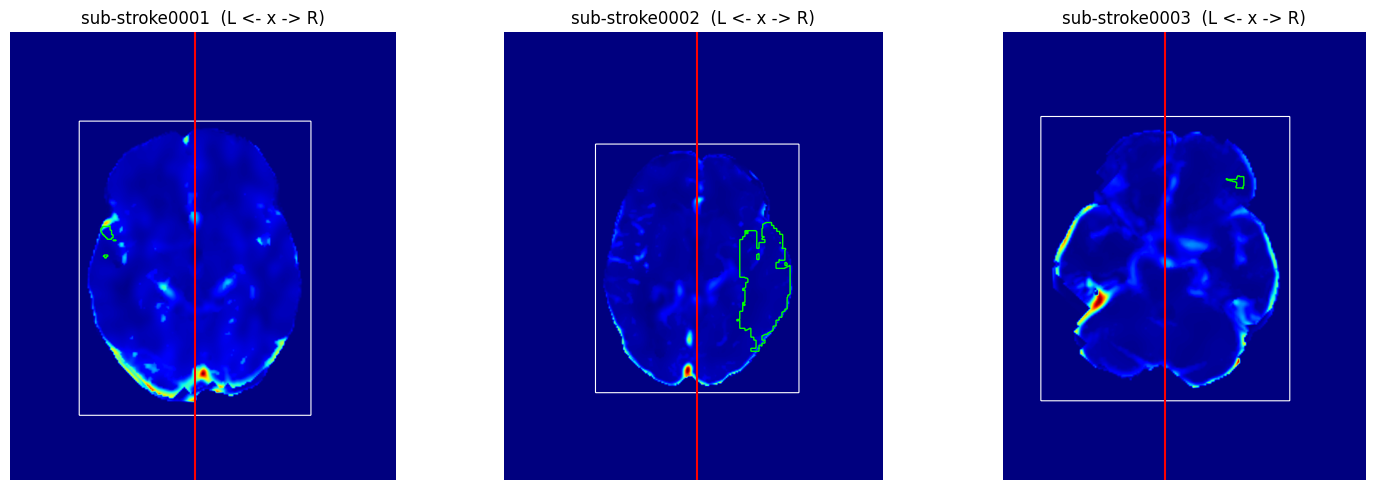

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, sh in zip(axes, shards[:3]):
    meta, vols, mask, codes, zooms = load_patient(sh)
    brain = make_brain_mask(vols); mid, xmin, xmax = find_midline(brain)
    z = int(np.argmax(brain.sum(axis=(0, 1))))
    ax.imshow(np.nan_to_num(vols['cbf'][:, :, z]).T, cmap='jet', origin='lower')
    ax.contour(brain[:, :, z].T, colors='white', linewidths=0.8)
    ax.contour(mask[:, :, z].T, colors='lime', linewidths=1.0)
    ax.axvline(mid, color='red', lw=1.5)
    ax.set_title(f"{meta['subject_id']}  (L <- x -> R)"); ax.axis('off')
    print(meta['subject_id'], '| axis code:', codes, '| voxel mm:', np.round(zooms, 2), '| midline x =', mid, 'of', brain.shape[0])
    for k in MAPS:
        v = vols[k][brain]; v = v[np.isfinite(v)]
        print(f'   {k}: p1={np.percentile(v,1):.2f}  median={np.median(v):.2f}  p99={np.percentile(v,99):.2f}')
plt.tight_layout(); plt.show()

## 5. Run all 149 patients (resumable, ~15-40 min)
One patient at a time; each result is saved to `week2_cache/` immediately. If Colab disconnects, re-run this cell — finished patients are skipped. A patient that errors is logged and skipped, not fatal.

In [ ]:
def process_patient(shard):
    meta, vols, mask, codes, zooms = load_patient(shard)
    row = dict(meta)
    if mask is None or any(v is None for v in vols.values()):
        row['error'] = 'missing map or mask'
        return row, None
    brain = make_brain_mask(vols)
    mid, xmin, xmax = find_midline(brain)
    row.update(brain_voxels=int(brain.sum()), midline_x=mid, x_extent=xmax - xmin,
               midline_offset_from_center=mid - brain.shape[0] / 2.0)
    row.update(asymmetry_features(vols, brain, mid))
    row.update(lesion_descriptors(vols, mask, brain, mid, zooms))
    return row, make_slices(vols, brain, mid)

def jdefault(o):
    return o.item() if hasattr(o, 'item') else str(o)

errors = []
for sh in tqdm(shards):
    sid = os.path.basename(sh).replace('.parquet', '')
    jpath, npath = os.path.join(CACHE, sid + '.json'), os.path.join(CACHE, sid + '.npy')
    if os.path.exists(jpath):
        continue
    try:
        row, sl = process_patient(sh)
        if sl is not None:
            np.save(npath, sl)
        with open(jpath, 'w') as fh:
            json.dump(row, fh, default=jdefault)
    except Exception as e:
        errors.append((sid, repr(e))); print('FAILED', sid, repr(e))
    gc.collect()
print('done. errors:', errors)

  0%|          | 0/149 [00:00<?, ?it/s]

done. errors: []


In [ ]:
# Assemble the cache into the two files we keep: the feature table + the slice tensor.
rows = [json.load(open(p)) for p in sorted(glob.glob(os.path.join(CACHE, '*.json')))]
df = pd.DataFrame(rows)
if 'error' in df.columns:
    print('Patients dropped (no usable data):'); print(df[df['error'].notna()][['subject_id', 'error']])
    df = df[df['error'].isna()].drop(columns='error')
df = df.reset_index(drop=True)
df.to_csv(FEATURES, index=False)

id_to_file = {json.load(open(p))['subject_id']: p.replace('.json', '.npy') for p in glob.glob(os.path.join(CACHE, '*.json'))}
X = np.stack([np.load(id_to_file[s]) for s in df['subject_id']])
np.savez_compressed(SLICES, X=X, subject_ids=df['subject_id'].values)
print('feature table:', df.shape, '| slice tensor:', X.shape, X.dtype)
df.head(3)

feature table: (149, 77) | slice tensor: (149, 8, 4, 96, 96) float16


,subject_id,age,sex,nihss_admission,x_axis_code,brain_voxels,midline_x,x_extent,midline_offset_from_center,cbf_mean_L,...,les_cbf_rest,les_cbv_lesion,les_cbv_mirror,les_cbv_rest,les_mtt_lesion,les_mtt_mirror,les_mtt_rest,les_tmax_lesion,les_tmax_mirror,les_tmax_rest
0,sub-stroke0001,61.0,M,5.0,L,5011782,245.5,307,-10.5,11.142467,...,11.308409,3.067495,2.088984,2.607237,18.623346,5.910804,4.345455,8.097036,2.128055,1.466012
1,sub-stroke0002,85.0,F,8.0,L,3851922,261.0,274,5.0,13.347224,...,12.161849,3.058174,3.286343,1.687638,5.445997,7.569381,-2.311417,4.795735,1.884916,0.975760
2,sub-stroke0003,81.0,F,21.0,L,5907433,229.5,351,-26.5,20.915209,...,20.755590,5.122704,1.534531,2.957867,15.948047,6.382009,5.222533,8.852780,3.452421,2.578697


### 5b. Re-label from the raw expert mask (fast; safe to re-run)
Reads **only the lesion mask** for each patient (no maps), recomputes the target and failure-analysis columns from the *raw* mask, and drops any patient whose expert mask is genuinely empty (nothing to locate). Needed if your table came from an earlier version of this notebook; harmless otherwise.

In [ ]:
sid_to_shard = {}
for p in glob.glob(os.path.join(CACHE, '*.json')):
    sid_to_shard[json.load(open(p))['subject_id']] = os.path.join(PROJECT, 'data', os.path.basename(p).replace('.json', '.parquet'))

new_cols = []
for _, r in tqdm(df.iterrows(), total=len(df)):
    row = None
    shard = sid_to_shard[r['subject_id']]
    for t in range(4):                                   # same Drive-retry idea as before
        try:
            row = pq.read_table(shard, columns=['lesion_mask']).slice(0, 1).to_pylist()[0]; break
        except OSError:
            print('Drive hiccup - remounting'); time.sleep(5); drive.mount('/content/drive', force_remount=True)
    arr, codes, zooms = load_nifti(row['lesion_mask'])
    m = arr > 0
    if codes[0] == 'L':
        m = np.ascontiguousarray(m[::-1])
    new_cols.append(label_descriptors(m, int(r['brain_voxels']), float(r['midline_x']), zooms))
    del m, arr; gc.collect()

new = pd.DataFrame(new_cols, index=df.index)
for c in new.columns:
    df[c] = new[c]
empty = df[df['lesion_left'].isna()]
print('Patients with an EMPTY expert mask (excluded from the study):', empty['subject_id'].tolist())
df = df[df['lesion_left'].notna()].reset_index(drop=True)
df['lesion_left'] = df['lesion_left'].astype(int)
df.to_csv(FEATURES, index=False)
print('final patients:', len(df), '| left:', int(df['lesion_left'].sum()), '| right:', int((1 - df['lesion_left']).sum()))

  0%|          | 0/149 [00:00<?, ?it/s]

Patients with an EMPTY expert mask (excluded from the study): ['sub-stroke0141', 'sub-stroke0162']
final patients: 147 | left: 83 | right: 64


## 6. EDA — do asymmetry features carry real signal? (Research Question 1)
Define which columns are model inputs vs. answer key, then three charts.

In [ ]:
df = pd.read_csv(FEATURES)
FEATURE_COLS = [c for c in df.columns if c.split('_')[0] in MAPS and df[c].nunique() > 1]   # cbf_*, cbv_*, mtt_*, tmax_* (constants dropped) -> allowed model inputs
ANSWER_COLS  = [c for c in df.columns if c.startswith(('lesion_', 'les_'))]   # NEVER model inputs
y = df['lesion_left'].values
assert not set(FEATURE_COLS) & set(ANSWER_COLS)
print(len(FEATURE_COLS), 'candidate features |', len(ANSWER_COLS), 'answer-key/descriptor columns')

45 candidate features | 22 answer-key/descriptor columns


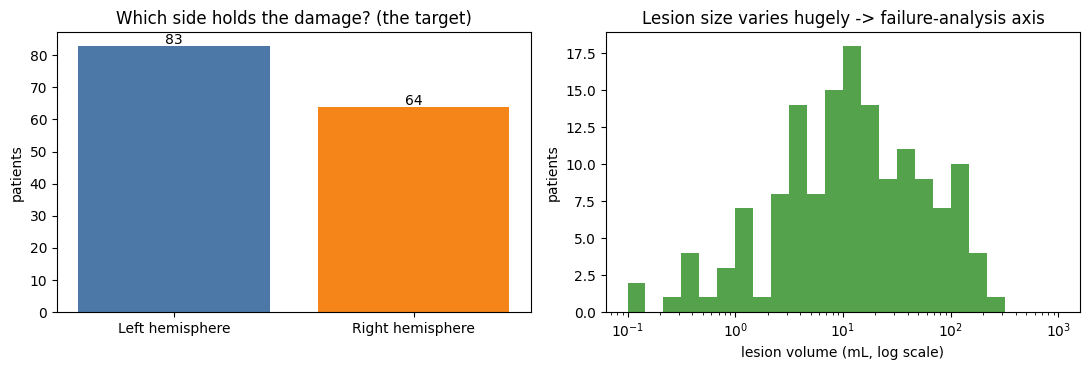

majority-class baseline accuracy: 0.565


In [ ]:
# CHART 1 - what are we predicting? class balance + lesion sizes
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
cnt = df['lesion_left'].value_counts().reindex([1, 0]).fillna(0)
ax[0].bar(['Left hemisphere', 'Right hemisphere'], cnt.values, color=['#4C78A8', '#F58518'])
for i, v in enumerate(cnt.values): ax[0].text(i, v + 0.5, int(v), ha='center')
ax[0].set_title('Which side holds the damage? (the target)'); ax[0].set_ylabel('patients')
ax[1].hist(df['lesion_ml'].clip(lower=0.1), bins=np.logspace(-1, 3, 25), color='#54A24B')
ax[1].set_xscale('log'); ax[1].set_xlabel('lesion volume (mL, log scale)'); ax[1].set_ylabel('patients')
ax[1].set_title('Lesion size varies hugely -> failure-analysis axis')
plt.tight_layout(); plt.show()
print('majority-class baseline accuracy:', round(max(y.mean(), 1 - y.mean()), 3))

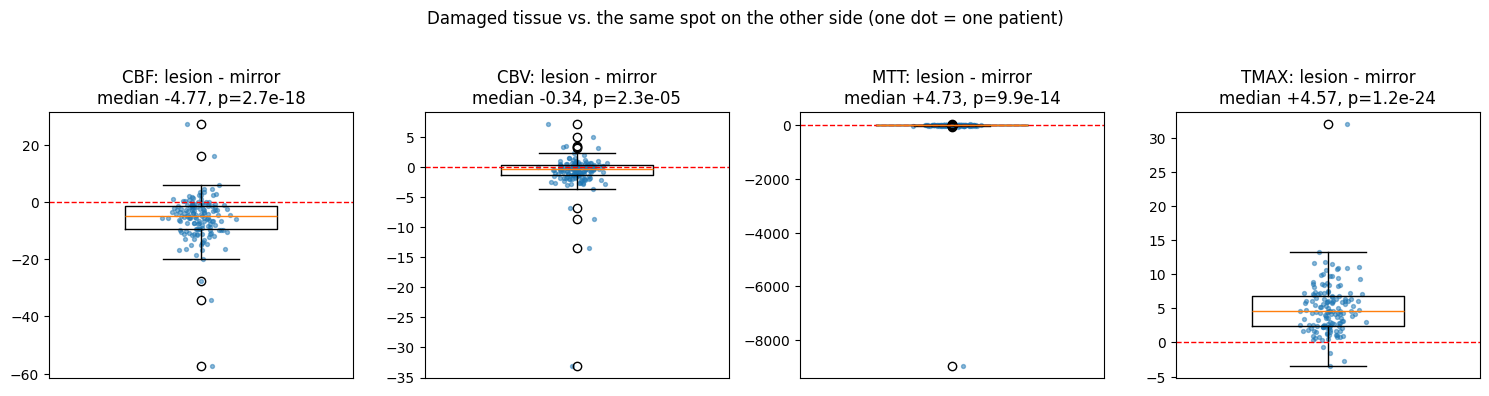

In [ ]:
# CHART 2 - the core proof, at tissue level: lesion tissue vs. its mirror-image spot on the healthy side
from scipy.stats import wilcoxon
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, k in zip(axes, MAPS):
    d = (df[f'les_{k}_lesion'] - df[f'les_{k}_mirror']).dropna()
    ax.boxplot(d, widths=0.5); ax.axhline(0, color='red', ls='--', lw=1)
    ax.scatter(np.random.normal(1, 0.04, len(d)), d, s=8, alpha=0.5)
    p = wilcoxon(d).pvalue
    ax.set_title(f'{k.upper()}: lesion - mirror\nmedian {d.median():+.2f}, p={p:.1e}'); ax.set_xticks([])
plt.suptitle('Damaged tissue vs. the same spot on the other side (one dot = one patient)', y=1.03)
plt.tight_layout(); plt.show()

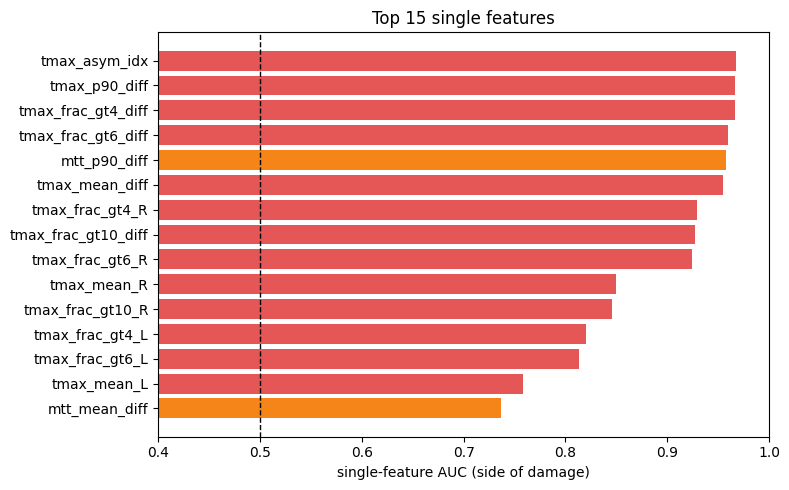

features with AUC > 0.7: 17 of 45


In [ ]:
# CHART 3 - how well does each single feature tell left strokes from right strokes? (univariate AUC, 0.5 = coin flip)
from sklearn.metrics import roc_auc_score
res = []
for c in FEATURE_COLS:
    s = df[c]; ok = s.notna()
    if ok.sum() > 20 and s[ok].nunique() > 1 and len(set(y[ok])) == 2:
        a = roc_auc_score(y[ok], s[ok]); res.append((c, max(a, 1 - a)))
auc = pd.DataFrame(res, columns=['feature', 'auc']).sort_values('auc', ascending=False)
top = auc.head(15).iloc[::-1]
colors = {'cbf': '#4C78A8', 'cbv': '#72B7B2', 'mtt': '#F58518', 'tmax': '#E45756'}
plt.figure(figsize=(8, 5))
plt.barh(top['feature'], top['auc'], color=[colors[f.split('_')[0]] for f in top['feature']])
plt.axvline(0.5, color='k', ls='--', lw=1); plt.xlim(0.4, 1.0)
plt.xlabel('single-feature AUC (side of damage)'); plt.title('Top 15 single features')
plt.tight_layout(); plt.show()
print('features with AUC > 0.7:', int((auc['auc'] > 0.7).sum()), 'of', len(auc))

## 7. Data hygiene — missingness, outliers, class balance
We **flag**, we don't silently delete. Anything removed gets reported in the paper/deck.

In [ ]:
print('--- Missing values (columns with any) ---')
miss = df[FEATURE_COLS + ANSWER_COLS].isna().sum(); print(miss[miss > 0] if (miss > 0).any() else 'none')

print('\n--- Constant columns (auto-excluded from FEATURE_COLS) ---')
print([c for c in df.columns if c.split('_')[0] in MAPS and df[c].nunique() <= 1] or 'none')

print('\n--- Outliers: robust z-score (median/MAD); patients with many extreme features ---')
X_ = df[FEATURE_COLS]
mad = (X_ - X_.median()).abs().median().replace(0, np.nan)
z = (X_ - X_.median()) / (1.4826 * mad)
df['n_extreme_feats'] = (z.abs() > 6).sum(axis=1)
print(df.sort_values('n_extreme_feats', ascending=False)[['subject_id', 'n_extreme_feats', 'lesion_ml']].head(8).to_string(index=False))

print('\n--- Class balance (target) ---')
print(df['lesion_left'].value_counts().rename({1: 'left', 0: 'right'}).to_string())
print('\n--- Failure-analysis groups (so each has enough patients to say something) ---')
print('bilateral (>=10% of lesion on other side):', int(df['lesion_bilateral'].sum()))
print('lesion volume quartiles (mL):', df['lesion_ml'].quantile([0, .25, .5, .75, 1]).round(1).tolist())
print('lesion centre within 10 mm of midline:', int((df['lesion_mid_dist_mm'] < 10).sum()))

print('\n--- Pipeline sanity ---')
print('x-axis codes seen (before standardising):', df['x_axis_code'].value_counts().to_dict())
print('midline offset from array centre (voxels): min/median/max =',
      round(float(df['midline_offset_from_center'].min()), 1), round(float(df['midline_offset_from_center'].median()), 1), round(float(df['midline_offset_from_center'].max()), 1))
print('patients whose lesion lies (partly) outside the brain mask (no mirror stats):', df.loc[df['les_cbf_lesion'].isna(), 'subject_id'].tolist())
print('patients with lesion_voxels == 0:', int((df['lesion_voxels'] == 0).sum()), '(should be 0)')
df.to_csv(FEATURES, index=False)

--- Missing values (columns with any) ---
lesion_mirror_valid_frac    1
les_cbf_lesion              1
les_cbf_mirror              1
les_cbf_rest                1
les_cbv_lesion              1
les_cbv_mirror              1
les_cbv_rest                1
les_mtt_lesion              1
les_mtt_mirror              1
les_mtt_rest                1
les_tmax_lesion             1
les_tmax_mirror             1
les_tmax_rest               1
dtype: int64

--- Constant columns (auto-excluded from FEATURE_COLS) ---
['tmax_p10_diff']

--- Outliers: robust z-score (median/MAD); patients with many extreme features ---
    subject_id  n_extreme_feats  lesion_ml
sub-stroke0026               10  29.612767
sub-stroke0021                5   7.195605
sub-stroke0007                4  61.865229
sub-stroke0188                4  12.077056
sub-stroke0099                4   1.075451
sub-stroke0030                3  14.136997
sub-stroke0040                3  14.919853
sub-stroke0022                3  28.548241

--- C

## 8. Lock the patient-level split now (used by BOTH models)
Doing this once, here, and saving it to disk is what guarantees **identical held-out patients** for both models — the heart of the "fair comparison" claim. 5 folds, stratified on the target, split by **patient** (never by slice).

In [ ]:
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
df['fold'] = -1
for f, (_, te) in enumerate(skf.split(df, df['lesion_left'])):
    df.loc[te, 'fold'] = f
df[['subject_id', 'fold', 'lesion_left']].to_csv(FOLDS, index=False)
df.to_csv(FEATURES, index=False)
print(pd.crosstab(df['fold'], df['lesion_left'].map({1: 'left', 0: 'right'})))

lesion_left  left  right
fold                    
0              17     13
1              17     13
2              17     12
3              16     13
4              16     13


## 9. Image-model scaffold (the foil — keep it small!)
A tiny CNN: 4 conv blocks -> flatten -> 1 output. Two deliberate design choices, so the foil is a *fair* opponent rather than a strawman:
- **No global average pooling.** That would make the network blind to *where* in the image something is — and "left vs. right" is entirely about position. We flatten instead.
- **Mirror augmentation:** flip an image left<->right *and swap its label*. That's a valid new example (a left stroke mirrored is a right stroke). **In Week 3 give the simple model the same trick** (swap L/R columns and negate the diffs) so both sides get equal tuning effort.

Patient-level prediction = average the slice predictions per patient. The training below is a **smoke test only** (2-3 epochs, fold 0) — to prove the plumbing runs end to end. **Don't read anything into its score.**

In [ ]:
import torch, torch.nn as nn
from sklearn.metrics import roc_auc_score
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev, '(CPU is fine for this size)')

d = np.load(SLICES, allow_pickle=True)
keep = [i for i, sid in enumerate(d['subject_ids']) if sid in set(df['subject_id'])]   # drops any patient excluded in 5b
X_all = d['X'][keep].astype(np.float32)                     # (patients, 8 slices, 4 maps, 96, 96)
ids = [d['subject_ids'][i] for i in keep]

# Sanitise: float16 overflow made some voxels inf/NaN. Fixed physiological caps (not data-derived -> no leakage).
CAPS = np.array([150, 40, 40, 20], dtype=np.float32).reshape(1, 1, 4, 1, 1)   # cbf, cbv, mtt, tmax
n_bad = int((~np.isfinite(X_all)).sum())
X_all = np.nan_to_num(X_all, nan=0.0, posinf=1e9, neginf=0.0)
X_all = np.clip(X_all, 0, CAPS)
print(f'fixed {n_bad:,} non-finite values | any left: {not np.isfinite(X_all).all()} | per-channel max: {X_all.max(axis=(0,1,3,4))}')

tab = df.set_index('subject_id').loc[ids]
y_all, fold_all = tab['lesion_left'].values.astype(np.float32), tab['fold'].values
print(X_all.shape)

class SmallCNN(nn.Module):
    def __init__(self, in_ch=4):
        super().__init__()
        blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.body = nn.Sequential(blk(in_ch, 16), blk(16, 32), blk(32, 64), blk(64, 64))   # 96 -> 6
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 6 * 6, 1))
    def forward(self, x):
        return self.head(self.body(x)).squeeze(1)

model = SmallCNN().to(dev)
n_params = sum(p.numel() for p in model.parameters())
print(f'parameters: {n_params:,}')

device: cuda (CPU is fine for this size)
fixed 7 non-finite values | any left: False | per-channel max: [150.  40.  40.  20.]
(147, 8, 4, 96, 96)
parameters: 63,313


In [ ]:
def run_fold(test_fold, epochs=3, lr=1e-3, bs=64, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    tr, te = np.where(fold_all != test_fold)[0], np.where(fold_all == test_fold)[0]
    # slice-level training set built ONLY from training patients
    Xtr = X_all[tr].reshape(-1, 4, 96, 96); ytr = np.repeat(y_all[tr], X_all.shape[1])
    mu = Xtr.mean(axis=(0, 2, 3), keepdims=True); sd = Xtr.std(axis=(0, 2, 3), keepdims=True) + 1e-6
    norm = lambda a: (a - mu) / sd
    Xtr_t, ytr_t = torch.tensor(norm(Xtr)), torch.tensor(ytr)
    net = SmallCNN().to(dev); opt = torch.optim.Adam(net.parameters(), lr=lr); lossf = nn.BCEWithLogitsLoss()
    t0 = time.time()
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(Xtr_t)); tot = 0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]; xb, yb = Xtr_t[idx].clone(), ytr_t[idx].clone()
            flip = torch.rand(len(xb)) < 0.5                  # mirror augmentation: flip X axis AND swap label
            xb[flip] = xb[flip].flip(2); yb[flip] = 1 - yb[flip]
            xb, yb = xb.to(dev), yb.to(dev)
            opt.zero_grad(); loss = lossf(net(xb), yb); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        print(f'epoch {ep + 1}/{epochs}  train loss {tot / len(perm):.3f}')
    train_secs = time.time() - t0
    net.eval()
    with torch.no_grad():
        Xte = torch.tensor(norm(X_all[te].reshape(-1, 4, 96, 96))).to(dev)
        p = torch.sigmoid(net(Xte)).cpu().numpy().reshape(len(te), -1).mean(axis=1)   # average slices -> one number per PATIENT
    return roc_auc_score(y_all[te], p), train_secs

auc_smoke, secs = run_fold(test_fold=0)
print(f'\nSMOKE TEST ONLY -> fold-0 patient-level AUC {auc_smoke:.2f}, training time {secs:.0f}s, params {n_params:,}')
print('If this ran without errors, the image-model scaffold works. Real training + tuning is Week 3.')

epoch 1/3  train loss 0.635
epoch 2/3  train loss 0.439
epoch 3/3  train loss 0.415

SMOKE TEST ONLY -> fold-0 patient-level AUC 0.95, training time 4s, params 63,313
If this ran without errors, the image-model scaffold works. Real training + tuning is Week 3.


## 10. Week 2 checklist & decision gate

In [ ]:
checks = {
    'Feature table saved (one row per patient)':      os.path.exists(FEATURES) and len(df) >= 140,
    'Features are signed (left minus right)':         'tmax_mean_diff' in df.columns,
    'Target defined & not constant':                  df['lesion_left'].nunique() == 2,
    'Both classes reasonably balanced (min >= 25%)':  min(df['lesion_left'].mean(), 1 - df['lesion_left'].mean()) >= 0.25,
    'Patient-level folds saved':                      os.path.exists(FOLDS),
    'Image-model scaffold ran':                       'auc_smoke' in globals(),
    'No answer-key column among features':            not set(FEATURE_COLS) & set(ANSWER_COLS),
}
for k, v in checks.items(): print('[x]' if v else '[ ]', k)
print('\nDECISION GATE: if all boxes are ticked and the Chart-2 / Chart-3 signal looks real, you are AHEAD -> greenlight the')
print('optional Week-3 generalization stress-test. If you are still fighting the pipeline, DROP it and protect the core comparison.')

[x] Feature table saved (one row per patient)
[x] Features are signed (left minus right)
[x] Target defined & not constant
[x] Both classes reasonably balanced (min >= 25%)
[x] Patient-level folds saved
[x] Image-model scaffold ran
[x] No answer-key column among features

DECISION GATE: if all boxes are ticked and the Chart-2 / Chart-3 signal looks real, you are AHEAD -> greenlight the
optional Week-3 generalization stress-test. If you are still fighting the pipeline, DROP it and protect the core comparison.


In [ ]:
# Functions

CACHE2 = os.path.join(PROJECT, 'week2b_cache'); os.makedirs(CACHE2, exist_ok=True)
THIRDS = ['post', 'mid', 'ant']                       # y axis standardised so higher index = anterior (front)
REGIONS = ['L_post', 'L_mid', 'L_ant', 'R_post', 'R_mid', 'R_ant']
MIN_REGION_ML = 0.5          # region counts as "damaged" if it holds >= 0.5 mL of lesion (the biggest region always counts)
MIN_SLICE_VOX = 50           # same idea per slice, for the image model's slice-level labels

def third_index(brain):
    ymin, ymax = find_extent(brain, (0, 2))
    edges = np.linspace(ymin, ymax + 1, 4)
    return np.digitize(np.arange(brain.shape[1]), edges[1:3])        # 0,1,2 along y

def region_selectors(brain, mid, third):
    xi = np.arange(brain.shape[0])[:, None, None]; ti = third[None, :, None]
    sel = {}
    for side, sx in (('L', xi < mid), ('R', xi > mid)):
        for t, tn in enumerate(THIRDS):
            sel[f'{side}_{tn}'] = sx & (ti == t)
    return sel

def _m(a):
    a = a[np.isfinite(a)]
    return float(a.mean()) if len(a) else np.nan

def regional_features(vols, brain, sel):
    f = {}
    for tn in THIRDS:
        sL, sR = brain & sel[f'L_{tn}'], brain & sel[f'R_{tn}']
        for k in MAPS:
            lm, rm = _m(vols[k][sL]), _m(vols[k][sR])
            f[f'{k}_{tn}_mean_L'], f[f'{k}_{tn}_mean_R'] = lm, rm
            f[f'{k}_{tn}_mean_diff'] = lm - rm
            f[f'{k}_{tn}_asym_idx'] = (lm - rm) / (0.5 * (abs(lm) + abs(rm)) + 1e-6)
        for thr in (4, 6):
            fl = _m((vols['tmax'][sL] > thr).astype(np.float32)); fr = _m((vols['tmax'][sR] > thr).astype(np.float32))
            f[f'tmax_{tn}_frac_gt{thr}_L'], f[f'tmax_{tn}_frac_gt{thr}_R'] = fl, fr
            f[f'tmax_{tn}_frac_gt{thr}_diff'] = fl - fr
    return f

def region_labels(mask, sel, zooms):
    vox_ml = float(np.prod(zooms)) / 1000.0
    ml = np.array([float((mask & sel[r]).sum()) * vox_ml for r in REGIONS])
    pos = ml >= MIN_REGION_ML
    if ml.sum() > 0 and not pos.any():
        pos[ml.argmax()] = True
    out = {f'reg_{r}_ml': float(m) for r, m in zip(REGIONS, ml)}
    out.update({f'reg_{r}': int(p) for r, p in zip(REGIONS, pos)})
    return out

def pick_slices(brain, n=8):
    area = brain.sum(axis=(0, 1)); good = np.nonzero(area >= 0.2 * area.max())[0]
    return np.round(np.linspace(good.min(), good.max(), n)).astype(int)

def make_slices2(vols, brain, mid, zs, size=96):
    xmin, xmax = find_extent(brain, (1, 2)); ymin, ymax = find_extent(brain, (0, 2))
    half = max(mid - xmin, xmax - mid)
    side = int(np.ceil(max(2 * half, ymax - ymin))) + 2
    x0, y0 = int(round(mid - side / 2)), int(round((ymin + ymax) / 2 - side / 2))
    out = np.zeros((len(zs), 4, size, size), np.float16)               # (slice, map, X left->right, Y post->ant)
    for i, z in enumerate(zs):
        for c, k in enumerate(MAPS):
            sl = np.where(brain[:, :, z], vols[k][:, :, z], 0).astype(np.float32)
            sl[~np.isfinite(sl)] = 0
            sl = np.clip(sl, 0, 150)                                    # cap -> no float16 overflow
            out[i, c] = fit_to(ndi.zoom(crop_pad(sl, x0, y0, side), size / side, order=1), size)
    return out

def slice_region_labels(mask, sel, zs):
    lab = np.zeros((len(zs), len(REGIONS)), np.int8)
    for i, z in enumerate(zs):
        for j, r in enumerate(REGIONS):
            lab[i, j] = int((mask[:, :, z] & sel[r][:, :, z] if sel[r].shape[2] > 1 else mask[:, :, z] & sel[r][:, :, 0]).sum() >= MIN_SLICE_VOX)
    return lab

def process_patient_B(shard):
    meta, vols, mask, codes, zooms = load_patient(shard)              # x already standardised left->right
    row = {'subject_id': meta['subject_id'], 'y_axis_code': codes[1]}
    if mask is None or any(v is None for v in vols.values()):
        row['error'] = 'missing map or mask'; return row, None, None
    if codes[1] == 'P':                                                # standardise: higher y = anterior
        vols = {k: np.ascontiguousarray(v[:, ::-1]) for k, v in vols.items()}; mask = np.ascontiguousarray(mask[:, ::-1])
    brain = make_brain_mask(vols); mid, _, _ = find_midline(brain)
    third = third_index(brain); sel = region_selectors(brain, mid, third)
    row.update(regional_features(vols, brain, sel)); row.update(region_labels(mask, sel, zooms))
    zs = pick_slices(brain)
    return row, make_slices2(vols, brain, mid, zs), slice_region_labels(mask, sel, zs)

In [ ]:
errors = []
for sh in tqdm(shards):
    stem = os.path.basename(sh).replace('.parquet', '')
    jp, np_ = os.path.join(CACHE2, stem + '.json'), os.path.join(CACHE2, stem + '.npz')
    if os.path.exists(jp):
        continue
    try:
        row, sl, lab = process_patient_B(sh)
        if sl is not None:
            np.savez(np_, X=sl, lab=lab)
        with open(jp, 'w') as fh:
            json.dump(row, fh, default=jdefault)
    except Exception as e:
        errors.append((stem, repr(e))); print('FAILED', stem, repr(e))
    gc.collect()
print('done. errors:', errors)

  0%|          | 0/149 [00:00<?, ?it/s]

done. errors: []


In [ ]:
# Assemble and sanity-check

rowsB = [json.load(open(p)) for p in sorted(glob.glob(os.path.join(CACHE2, '*.json')))]
dfB = pd.DataFrame(rowsB)
if 'error' in dfB.columns:
    dfB = dfB[dfB['error'].isna()].drop(columns='error')
dfm = df.merge(dfB, on='subject_id', how='inner').reset_index(drop=True)      # df = your cleaned table from Week 2 (empty-mask patients already gone)

Xs, Ls = [], []
for sid in dfm['subject_id']:
    stem = [os.path.basename(p)[:-5] for p in glob.glob(os.path.join(CACHE2, '*.json')) if json.load(open(p))['subject_id'] == sid][0]
    z = np.load(os.path.join(CACHE2, stem + '.npz')); Xs.append(z['X']); Ls.append(z['lab'])
np.savez_compressed(os.path.join(PROJECT, 'slices_v2.npz'), X=np.stack(Xs), Y_slice=np.stack(Ls), subject_ids=dfm['subject_id'].values)
dfm.to_csv(os.path.join(PROJECT, 'features_v2.csv'), index=False)
print('patients:', len(dfm), '| slice tensor:', np.stack(Xs).shape, '| y-axis codes:', dfm['y_axis_code'].value_counts().to_dict())

print('\n--- Region prevalence (share of patients with damage in each region) ---')
print(dfm[[f'reg_{r}' for r in REGIONS]].mean().round(2).to_string())
print('\nregions damaged per patient:', dfm[[f'reg_{r}' for r in REGIONS]].sum(axis=1).value_counts().sort_index().to_dict())

# consistency: hemisphere from regional volumes should match the Level-1 label
hemi = (dfm[[f'reg_L_{t}_ml' for t in THIRDS]].sum(axis=1) > dfm[[f'reg_R_{t}_ml' for t in THIRDS]].sum(axis=1)).astype(int)
print('\nLevel-1 label disagreements vs regional volumes:', int((hemi != dfm['lesion_left']).sum()), '(should be ~0)')

# quick look: does each region have signal? best single feature per region (AUC)
from sklearn.metrics import roc_auc_score
rg_cols = [c for c in dfm.columns if c.split('_')[0] in MAPS and any(f'_{t}_' in c for t in THIRDS) and dfm[c].nunique() > 1]
print('\n--- Best single regional feature per region (AUC) ---')
for r in REGIONS:
    yy = dfm[f'reg_{r}'].values
    if len(set(yy)) < 2: print(r, 'constant label'); continue
    best = sorted(((max(roc_auc_score(yy[dfm[c].notna()], dfm[c].dropna()), 1 - roc_auc_score(yy[dfm[c].notna()], dfm[c].dropna())), c) for c in rg_cols), reverse=True)[:2]
    print(f'{r}: ', [(round(a, 3), c) for a, c in best])

patients: 147 | slice tensor: (147, 8, 4, 96, 96) | y-axis codes: {'A': 100, 'P': 47}

--- Region prevalence (share of patients with damage in each region) ---
reg_L_post    0.33
reg_L_mid     0.56
reg_L_ant     0.25
reg_R_post    0.22
reg_R_mid     0.48
reg_R_ant     0.28

regions damaged per patient: {1: 41, 2: 61, 3: 35, 4: 8, 5: 1, 6: 1}

Level-1 label disagreements vs regional volumes: 0 (should be ~0)

--- Best single regional feature per region (AUC) ---
L_post:  [(np.float64(0.735), 'tmax_mid_frac_gt4_R'), (np.float64(0.73), 'tmax_mid_frac_gt6_R')]
L_mid:  [(np.float64(0.923), 'tmax_mid_frac_gt4_diff'), (np.float64(0.923), 'tmax_mid_asym_idx')]
L_ant:  [(np.float64(0.929), 'tmax_ant_mean_diff'), (np.float64(0.926), 'tmax_ant_frac_gt4_diff')]
R_post:  [(np.float64(0.804), 'tmax_post_frac_gt6_diff'), (np.float64(0.801), 'tmax_post_frac_gt4_diff')]
R_mid:  [(np.float64(0.911), 'tmax_mid_frac_gt4_diff'), (np.float64(0.91), 'tmax_mid_asym_idx')]
R_ant:  [(np.float64(0.867), 'tmax_mi

In [ ]:
# Setup, features, and mirror augmentation

import pickle, warnings
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')

dfm = pd.read_csv(os.path.join(PROJECT, 'features_v2.csv'))
dfm = dfm.drop(columns='fold', errors='ignore').merge(pd.read_csv(FOLDS)[['subject_id', 'fold']], on='subject_id').reset_index(drop=True)

THIRDS  = ['post', 'mid', 'ant']
REGIONS = ['L_post', 'L_mid', 'L_ant', 'R_post', 'R_mid', 'R_ant']
TARGETS = ['lesion_left'] + [f'reg_{r}' for r in REGIONS]          # Level 1 + the six Level-2 regions
is_feat = lambda c: c.split('_')[0] in MAPS and dfm[c].nunique() > 1
GLOBAL   = [c for c in dfm.columns if is_feat(c) and not any(f'_{t}_' in c for t in THIRDS)]
REGIONAL = [c for c in dfm.columns if is_feat(c) and any(f'_{t}_' in c for t in THIRDS)]
FEATS = GLOBAL + REGIONAL
assert not set(FEATS) & {c for c in dfm.columns if c.startswith(('lesion_', 'les_', 'reg_'))}   # no answer-key columns
print(len(dfm), 'patients |', len(GLOBAL), 'global +', len(REGIONAL), 'regional features | folds:', sorted(dfm['fold'].unique()))

# ---- Mirror augmentation (left<->right): swap *_L/*_R columns, negate signed differences ----
def mirror_columns(cols):
    swap, neg = {}, []
    for c in cols:
        if c.endswith('_L') and c[:-2] + '_R' in cols:
            swap[c] = c[:-2] + '_R'; swap[c[:-2] + '_R'] = c
        elif c.endswith('_diff') or c.endswith('_asym_idx'):
            neg.append(c)
    return swap, neg
SWAP, NEG = mirror_columns(FEATS)

def mirror_X(X):
    M = X.copy()
    for a, b in SWAP.items(): M[a] = X[b].values
    for c in NEG:             M[c] = -X[c].values
    return M

PARTNER = {0: None, 1: 4, 2: 5, 3: 6, 4: 1, 5: 2, 6: 3}             # which label a region becomes when mirrored
def aug_xy(X, Y, t):
    ym = 1 - Y[:, 0] if t == 0 else Y[:, PARTNER[t]]
    return pd.concat([X, mirror_X(X)]), np.concatenate([Y[:, t], ym])

# sanity check: mirroring twice gives back the original table
assert np.allclose(mirror_X(mirror_X(dfm[FEATS])).fillna(0).values, dfm[FEATS].fillna(0).values)
print('mirror check passed')

147 patients | 45 global + 66 regional features | folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
mirror check passed


In [ ]:
MODELS = ['logreg', 'rf', 'gboost']          # each gets the SAME search budget: 4 settings, 3-fold inner CV, mirror augmentation
GRIDS = {'logreg': [{'C': c} for c in (0.01, 0.1, 1, 10)],
         'rf':     [{'max_depth': d, 'msl': m} for d in (3, 6) for m in (1, 3)],
         'gboost': [{'lr': l, 'max_depth': d} for l in (0.05, 0.1) for d in (2, 3)]}

def make_model(name, p):
    if name == 'logreg':
        return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                             LogisticRegression(C=p['C'], max_iter=3000, class_weight='balanced'))
    if name == 'rf':
        return make_pipeline(SimpleImputer(strategy='median'),
                             RandomForestClassifier(n_estimators=200, max_depth=p['max_depth'], min_samples_leaf=p['msl'],
                                                    class_weight='balanced', n_jobs=-1, random_state=0))
    return HistGradientBoostingClassifier(learning_rate=p['lr'], max_depth=p['max_depth'], max_iter=150, random_state=0)

def safe_auc(y, p):
    return roc_auc_score(y, p) if len(set(y)) == 2 else np.nan

def fit_tuned(name, Xtr, Ytr, t):
    # Tune on TRAINING patients only. Inner folds are grouped by patient, so a patient and its mirror image never straddle train/val.
    best_p, best = GRIDS[name][0], -1
    if len(set(Ytr[:, t])) < 2:
        return None
    for p in GRIDS[name]:
        sc = []
        for a, b in GroupKFold(n_splits=3).split(Xtr, Ytr[:, t], np.arange(len(Xtr))):
            if len(set(Ytr[a, t])) < 2: continue
            Xa, ya = aug_xy(Xtr.iloc[a], Ytr[a], t)
            sc.append(safe_auc(Ytr[b, t], make_model(name, p).fit(Xa, ya).predict_proba(Xtr.iloc[b])[:, 1]))
        s = np.nanmean(sc) if len(sc) else -1
        if s > best: best, best_p = s, p
    Xa, ya = aug_xy(Xtr, Ytr, t)
    return make_model(name, best_p).fit(Xa, ya)

def top_feature(Xtr, y):
    scores = {c: abs(safe_auc(y[Xtr[c].notna().values], Xtr[c].dropna().values) - 0.5) for c in FEATS if Xtr[c].notna().sum() > 20}
    return max(scores, key=lambda c: np.nan_to_num(scores[c]))

n, T = len(dfm), len(TARGETS)
Y = dfm[TARGETS].values.astype(int)
ALL = ['majority', 'best_single_feature'] + MODELS
oof = {m: np.full((n, T), np.nan) for m in ALL}
secs = {m: 0.0 for m in ALL}; sizes = {m: [] for m in ALL}

for f in range(5):
    tr, te = np.where(dfm['fold'] != f)[0], np.where(dfm['fold'] == f)[0]
    Xtr, Xte, Ytr = dfm.loc[tr, FEATS], dfm.loc[te, FEATS], Y[tr]
    for t in range(T):
        if len(set(Ytr[:, t])) < 2: continue
        oof['majority'][te, t] = Ytr[:, t].mean()                                  # naive floor: predicts the training prevalence
        t0 = time.time(); c = top_feature(Xtr, Ytr[:, t])                           # honest baseline: ONE best feature + threshold
        one = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(class_weight='balanced')).fit(Xtr[[c]], Ytr[:, t])
        oof['best_single_feature'][te, t] = one.predict_proba(Xte[[c]])[:, 1]; secs['best_single_feature'] += time.time() - t0
        for m in MODELS:
            t0 = time.time(); mdl = fit_tuned(m, Xtr, Ytr, t); secs[m] += time.time() - t0
            oof[m][te, t] = mdl.predict_proba(Xte)[:, 1]
            if t == 0: sizes[m].append(len(pickle.dumps(mdl)) / 1024)
    print(f'fold {f} done')

with open(os.path.join(PROJECT, 'oof_simple.pkl'), 'wb') as fh:
    pickle.dump({'oof': oof, 'targets': TARGETS, 'subject_ids': dfm['subject_id'].tolist(), 'secs': secs, 'sizes': sizes}, fh)

# ---------------- results ----------------
def fold_aucs(P, t):
    return [safe_auc(Y[dfm['fold'] == f, t], P[dfm['fold'] == f, t]) for f in range(5)]

print('\n=== LEVEL 1: which hemisphere? (ROC-AUC, mean +/- sd over 5 patient-level folds) ===')
for m in ALL:
    a = fold_aucs(oof[m], 0); P = oof[m][:, 0]; pos = Y[:, 0] == 1
    print(f'{m:22s} AUC {np.nanmean(a):.3f} +/- {np.nanstd(a):.3f} | sensitivity@0.5 {np.mean(P[pos] >= .5):.2f} | specificity@0.5 {np.mean(P[~pos] < .5):.2f}')

print('\n=== LEVEL 2: damage in each of 6 regions (ROC-AUC, mean over folds) ===')
tab2 = pd.DataFrame({m: [np.nanmean(fold_aucs(oof[m], t)) for t in range(1, T)] for m in ALL}, index=REGIONS)
tab2.loc['MACRO MEAN'] = tab2.mean()
print(tab2.round(3).to_string())

print('\n=== COMPUTE COST (whole experiment = 5 folds x 7 targets, incl. tuning) ===')
for m in ALL:
    print(f'{m:22s} train+tune {secs[m]:7.1f}s | model size (Level-1 fit) {np.mean(sizes[m]) if sizes[m] else float("nan"):8.1f} KB')

fold 0 done
fold 1 done
fold 2 done
fold 3 done
fold 4 done

=== LEVEL 1: which hemisphere? (ROC-AUC, mean +/- sd over 5 patient-level folds) ===
majority               AUC 0.500 +/- 0.000 | sensitivity@0.5 1.00 | specificity@0.5 0.00
best_single_feature    AUC 0.964 +/- 0.036 | sensitivity@0.5 0.94 | specificity@0.5 0.94
logreg                 AUC 0.954 +/- 0.034 | sensitivity@0.5 0.96 | specificity@0.5 0.91
rf                     AUC 0.977 +/- 0.039 | sensitivity@0.5 0.95 | specificity@0.5 0.95
gboost                 AUC 0.980 +/- 0.027 | sensitivity@0.5 0.96 | specificity@0.5 0.94

=== LEVEL 2: damage in each of 6 regions (ROC-AUC, mean over folds) ===
            majority  best_single_feature  logreg     rf  gboost
L_post           0.5                0.701   0.737  0.698   0.696
L_mid            0.5                0.903   0.897  0.940   0.927
L_ant            0.5                0.906   0.913  0.894   0.865
R_post           0.5                0.746   0.715  0.820   0.808
R_mid      

In [ ]:
# data header

import os, pickle, time, warnings
import numpy as np, pandas as pd
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')

REGIONS = ['L_post', 'L_mid', 'L_ant', 'R_post', 'R_mid', 'R_ant']
TARGETS = ['lesion_left'] + [f'reg_{r}' for r in REGIONS]
dfm = pd.read_csv(os.path.join(PROJECT, 'features_v2.csv'))
dfm = dfm.drop(columns='fold', errors='ignore').merge(pd.read_csv(FOLDS)[['subject_id', 'fold']], on='subject_id').reset_index(drop=True)
Y = dfm[TARGETS].values.astype(int)
n = len(dfm)
def safe_auc(y, p):
    return roc_auc_score(y, p) if len(set(y)) == 2 else np.nan
print(n, 'patients loaded')

147 patients loaded


In [ ]:
# the CNN, same folds and same tuning budget (4 settings × 3-fold inner CV)

import torch, torch.nn as nn
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev)
if dev == 'cpu':
    print('NO GPU: Runtime > Change runtime type > T4 GPU, then re-run Setup + C0 + this cell. On CPU this takes very long.')

# ---- data: slices_v2 (y-axis standardised: front = high index), aligned to dfm order ----
d = np.load(os.path.join(PROJECT, 'slices_v2.npz'), allow_pickle=True)
pos = {s: i for i, s in enumerate(d['subject_ids'])}
order = [pos[s] for s in dfm['subject_id']]
Xn = d['X'][order].astype(np.float32)                         # (patients, 8 slices, 4 maps, 96, 96)
Yslice = d['Y_slice'][order].astype(np.float32)               # (patients, 8, 6)  region has >= 50 lesion voxels in that slice
CAPS = np.array([150, 40, 40, 20], dtype=np.float32).reshape(1, 1, 4, 1, 1)
Xn = np.clip(np.nan_to_num(Xn, nan=0.0, posinf=0.0, neginf=0.0), 0, CAPS)
hemi = np.repeat(dfm['lesion_left'].values[:, None, None].astype(np.float32), Xn.shape[1], axis=1)
Y7 = np.concatenate([Yslice, hemi], axis=2)                    # per-slice targets: 6 regions + patient's hemisphere label
X_t, Y_t = torch.tensor(Xn).to(dev), torch.tensor(Y7).to(dev)
tt = lambda i: torch.as_tensor(np.asarray(i), device=dev)
print('slice tensor', tuple(X_t.shape), '| slice-label tensor', tuple(Y_t.shape))

class SmallCNN(nn.Module):
    # no global pooling: left/right is about POSITION, so we keep spatial layout (flatten)
    def __init__(self, n_out=7):
        super().__init__()
        blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.body = nn.Sequential(blk(4, 16), blk(16, 32), blk(32, 64), blk(64, 64))   # 96 -> 6
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 6 * 6, n_out))
    def forward(self, x):
        return self.head(self.body(x))
N_PARAMS = sum(p.numel() for p in SmallCNN().parameters())
print(f'CNN parameters: {N_PARAMS:,}')

def mirror_y(yb):        # mirrored image: left regions <-> right regions, hemisphere label flips
    return torch.cat([yb[:, 3:6], yb[:, 0:3], 1 - yb[:, 6:7]], dim=1)

def train_cnn(tr_idx, lr, epochs, seed=0, bs=64):
    torch.manual_seed(seed); np.random.seed(seed)
    Xtr, Ytr = X_t[tt(tr_idx)].reshape(-1, 4, 96, 96), Y_t[tt(tr_idx)].reshape(-1, 7)
    mu, sd = Xtr.mean(dim=(0, 2, 3), keepdim=True), Xtr.std(dim=(0, 2, 3), keepdim=True) + 1e-6     # from TRAIN patients only
    net = SmallCNN().to(dev); opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4); lossf = nn.BCEWithLogitsLoss()
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(Xtr), device=dev)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]; xb, yb = (Xtr[idx] - mu) / sd, Ytr[idx]
            flip = torch.rand(len(idx), device=dev) < 0.5                    # mirror augmentation (same trick the simple models got)
            xb = torch.where(flip[:, None, None, None], xb.flip(2), xb)
            yb = torch.where(flip[:, None], mirror_y(yb), yb)
            opt.zero_grad(); lossf(net(xb), yb).backward(); opt.step()
    return net, mu, sd

@torch.no_grad()
def predict_cnn(net, mu, sd, idx):
    net.eval(); Xte = X_t[tt(idx)].reshape(-1, 4, 96, 96)
    p = torch.cat([torch.sigmoid(net((Xte[i:i + 256] - mu) / sd)) for i in range(0, len(Xte), 256)])
    p = p.reshape(len(idx), Xte.shape[0] // len(idx), 7).cpu().numpy()
    P = np.zeros((len(idx), 7))
    P[:, 0] = p[:, :, 6].mean(axis=1)           # hemisphere score: average over slices   -> column order matches TARGETS
    P[:, 1:7] = p[:, :, :6].max(axis=1)         # region score: "does ANY slice show damage there"
    return P

# same search budget as every simple model: 4 settings x 3-fold inner CV (grouped by patient) on TRAINING patients only
SETTINGS = [{'lr': l, 'epochs': e} for l in (1e-3, 3e-3) for e in (10, 20)]
mean_auc = lambda Yt, P: np.nanmean([safe_auc(Yt[:, t], P[:, t]) for t in range(7)])

oof_cnn = np.full((n, 7), np.nan); train_secs, final_secs, infer_secs, chosen = [], [], [], []
for f in range(5):
    tr, te = np.where(dfm['fold'] != f)[0], np.where(dfm['fold'] == f)[0]
    t0 = time.time(); scores = []
    for s in SETTINGS:
        sc = []
        for a, b in GroupKFold(n_splits=3).split(tr, groups=np.arange(len(tr))):
            net, mu, sd = train_cnn(tr[a], s['lr'], s['epochs'])
            sc.append(mean_auc(Y[tr[b]], predict_cnn(net, mu, sd, tr[b])))
        scores.append(np.nanmean(sc))
    best = SETTINGS[int(np.nanargmax(scores))]; chosen.append(best)
    t1 = time.time(); net, mu, sd = train_cnn(tr, best['lr'], best['epochs']); final_secs.append(time.time() - t1)
    t2 = time.time(); oof_cnn[te] = predict_cnn(net, mu, sd, te); infer_secs.append((time.time() - t2) / len(te))
    train_secs.append(time.time() - t0)
    print(f'fold {f} done | chose {best} | {train_secs[-1]:.0f}s')

with open(os.path.join(PROJECT, 'oof_cnn.pkl'), 'wb') as fh:
    pickle.dump({'oof': oof_cnn, 'train_secs': train_secs, 'final_secs': final_secs, 'infer_secs': infer_secs,
                 'params': N_PARAMS, 'chosen': chosen, 'device': dev, 'subject_ids': dfm['subject_id'].tolist()}, fh)
fa = [safe_auc(Y[dfm['fold'] == f, 0], oof_cnn[dfm['fold'] == f, 0]) for f in range(5)]
print(f'\nCNN Level-1 AUC {np.nanmean(fa):.3f} +/- {np.nanstd(fa):.3f}   (full comparison in the next cell)')

device: cuda
slice tensor (147, 8, 4, 96, 96) | slice-label tensor (147, 8, 7)
CNN parameters: 77,143
fold 0 done | chose {'lr': 0.001, 'epochs': 10} | 27s
fold 1 done | chose {'lr': 0.003, 'epochs': 10} | 27s
fold 2 done | chose {'lr': 0.001, 'epochs': 10} | 28s
fold 3 done | chose {'lr': 0.001, 'epochs': 10} | 28s
fold 4 done | chose {'lr': 0.001, 'epochs': 20} | 30s

CNN Level-1 AUC 0.977 +/- 0.024   (full comparison in the next cell)


In [ ]:
# the head-to-head, plus three diagnostics

S = pickle.load(open(os.path.join(PROJECT, 'oof_simple.pkl'), 'rb')); C = pickle.load(open(os.path.join(PROJECT, 'oof_cnn.pkl'), 'rb'))
assert S['subject_ids'] == dfm['subject_id'].tolist() == C['subject_ids']
P = dict(S['oof']); P['cnn'] = C['oof']
hp = P['gboost'][:, 0]                                                   # NULL MODEL: "only knows the hemisphere, nothing about front/back"
H = np.full((n, 7), np.nan); H[:, 0] = hp; H[:, 1:4] = hp[:, None]; H[:, 4:7] = 1 - hp[:, None]
P['hemisphere_only'] = H
names = ['majority', 'best_single_feature', 'logreg', 'rf', 'gboost', 'cnn', 'hemisphere_only']
fold = dfm['fold'].values
fa = lambda Pm, t: [safe_auc(Y[fold == f, t], Pm[fold == f, t]) for f in range(5)]

print('=== LEVEL 1 (hemisphere): ROC-AUC mean +/- sd across 5 folds ===')
for m in names[:6]:
    a = fa(P[m], 0); print(f'{m:22s} {np.nanmean(a):.3f} +/- {np.nanstd(a):.3f}')

print('\n=== LEVEL 2 (6 regions): ROC-AUC, mean over folds ===')
t2 = pd.DataFrame({m: [np.nanmean(fa(P[m], t)) for t in range(1, 7)] for m in names}, index=REGIONS)
t2.loc['MACRO MEAN'] = t2.mean(); print(t2.round(3).to_string())

print('\n=== WITHIN-HEMISPHERE: given the true side, can it tell WHICH regions are hit? (pooled AUC) ===')
left = Y[:, 0] == 1
rows = {m: [safe_auc(Y[(left if t <= 3 else ~left), t], P[m][(left if t <= 3 else ~left), t]) for t in range(1, 7)] for m in names}
w = pd.DataFrame(rows, index=REGIONS); w.loc['MEAN'] = w.mean(); print(w.round(3).to_string())
print('(hemisphere_only should sit near 0.5 here: it knows the side but nothing about front/back)')

print('\n=== IS CNN vs SIMPLE A REAL DIFFERENCE? patient-level bootstrap, 95% CI of (CNN - model), pooled AUC ===')
rng = np.random.default_rng(0)
l1 = lambda Pm, i: safe_auc(Y[i, 0], Pm[i, 0])
mac = lambda Pm, i: np.nanmean([safe_auc(Y[i, t], Pm[i, t]) for t in range(1, 7)])
for m in ['best_single_feature', 'logreg', 'rf', 'gboost']:
    d1, d2 = [], []
    for _ in range(500):
        i = rng.integers(0, n, n)
        d1.append(l1(P['cnn'], i) - l1(P[m], i)); d2.append(mac(P['cnn'], i) - mac(P[m], i))
    c1, c2 = np.nanpercentile(d1, [2.5, 97.5]), np.nanpercentile(d2, [2.5, 97.5])
    print(f'CNN - {m:20s} L1: [{c1[0]:+.3f}, {c1[1]:+.3f}]   L2 macro: [{c2[0]:+.3f}, {c2[1]:+.3f}]   (interval containing 0 = no detectable difference)')

print('\n=== COMPUTE COST ===')
for m in ['best_single_feature', 'logreg', 'rf', 'gboost']:
    print(f'{m:22s} train+tune {S["secs"][m]:7.1f}s (CPU)')
print(f'{"cnn":22s} train+tune {sum(C["train_secs"]):7.1f}s ({C["device"]}) | {C["params"]:,} parameters | settings chosen: {[(c["lr"], c["epochs"]) for c in C["chosen"]]}')